## Packages

In [1]:
# Package imports
import numpy as np
import pandas as pd
import copy
import matplotlib.pyplot as plt
import sklearn
import sklearn.datasets
import sklearn.linear_model

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import MinMaxScaler

## Loading and Preparing Data

The data is read in and merged into one big dataset.

In [2]:
# Loading the data
weather_2021 = pd.read_csv("Data/ninja_weather_2021.csv", comment="#")
weather_2022 = pd.read_csv("Data/ninja_weather_2022.csv", comment="#")
weather_2023 = pd.read_csv("Data/ninja_weather_2023.csv", comment="#")
weather_2024 = pd.read_csv("Data/ninja_weather_2024.csv", comment="#")
weather_2025 = pd.read_csv("Data/ninja_weather_2025.csv", comment="#")

pv_2021 = pd.read_csv("Data/ninja_pv_2021.csv", comment="#")
pv_2022 = pd.read_csv("Data/ninja_pv_2022.csv", comment="#")
pv_2023 = pd.read_csv("Data/ninja_pv_2023.csv", comment="#")
pv_2024 = pd.read_csv("Data/ninja_pv_2024.csv", comment="#")
pv_2025 = pd.read_csv("Data/ninja_pv_2025.csv", comment="#")

# merge the three years
weather = pd.concat([weather_2021, weather_2022, weather_2023, weather_2024, weather_2025], ignore_index=True)
pv = pd.concat([pv_2021, pv_2022, pv_2023, pv_2024, pv_2025], ignore_index=True)

# merge weather and pv data
data = pd.merge(weather, pv, on="time")

data["time"] = pd.to_datetime(data["time"])    # timestamps as datetime
data = data.set_index("time")                  # datetime index

time = data.index                              # keep the timestamps
input_data = data.values                       # .values converts a pandas dataframe to a numpy array

In [3]:
#Categorizing the data into inputs (x) and outputs (y) as well as training set and testing set
split = int(0.8 * input_data.shape[0])   # 80 20 split

train_set_x_orig = input_data[:split, 0:8]
test_set_x_orig = input_data[split:, 0:8]
train_set_y_orig = input_data[:split, -1:]
test_set_y_orig = input_data[split:, -1:]

## Model (based on tutorial)


**Mathematical expression of the algorithm**:

$$
z^{(i)} = w^T x^{(i)} + b \tag{1}
$$

$$
\hat{y}^{(i)} = a^{(i)} = \sigma(z^{(i)}) \tag{2}
$$

$$
\mathcal{L}(a^{(i)}, y^{(i)}) = - y^{(i)} \log(a^{(i)}) - (1-y^{(i)}) \log(1-a^{(i)}) \tag{3}
$$


$$
J = \frac{1}{m} \sum_{i=1}^m \mathcal{L}(a^{(i)}, y^{(i)}) \tag{4}
$$


### Forward and Backward propagation

$$ \frac{\partial J}{\partial w} = \frac{1}{m}X(A-Y)^T\tag{5}$$
$$ \frac{\partial J}{\partial b} = \frac{1}{m} \sum_{i=1}^m (a^{(i)}-y^{(i)})\tag{6}$$

### Helper Functions

In [4]:
# Sigmoid function
def sigmoid(z):
    
    s = 1 / (1 + np.exp(-z))
    
    return s

#initilisation
def initialize_with_zeros(dim):

    w = np.zeros((dim, 1))
    b = float(0)

    return w, b

In [5]:

def propagate(w, b, X, Y):

    m = X.shape[1]                  
    A = sigmoid(np.dot(w.T, X) + b) 

    cost = -1/m * np.sum(Y * np.log(A) + (1 - Y) * np.log(1 - A))                       

    dw = 1/m * np.dot(X, (A - Y).T)

    db = 1/m * np.sum(A - Y)

    grads = {"dw": dw,
              "db": db}
   
    
    return grads, cost

### Optimization

In [6]:
def optimize(w, b, X, Y, num_iterations=2000, learning_rate=0.009, print_cost=False):

    w = copy.deepcopy(w)
    b = copy.deepcopy(b)

    costs = []

    for i in range(num_iterations):
        grads, cost = propagate(w, b, X, Y)

        dw = grads["dw"]
        db = grads["db"]

        w = w - learning_rate * dw
        b = b - learning_rate * db

        params = {"w": w,
                  "b": b}

        grads = {"dw": dw,
                  "db": db}

        if i % 100 == 0:
            costs.append(cost)

            # Print the cost every 100 training iterations
            if print_cost:
                print ("Cost after iteration %i: %f" %(i, cost))
    
    return params, grads, costs

### Predict

In [7]:
def predict(w, b, X):

    m = X.shape[1]
    Y_prediction = np.zeros((1, m))
    w = w.reshape(X.shape[0], 1)
    
    A = sigmoid(np.dot(w.T, X) + b)
    
    for i in range(A.shape[1]):
        
        Y_prediction[0,i] = A[0, i]
           
    return Y_prediction
    

### Evaluation based upon L9

In [8]:
# Evaluation
def evaluate(y_true, y_pred):
    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    r2 = 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - np.mean(y_true)) ** 2)
    return mae, rmse, r2


### Merge all functions into a model

In [9]:
def model(train_set_x_normalized, train_set_y_normalized , test_set_x_normalized, test_set_y_normalized, num_iterations=10000, learning_rate=.85, print_cost=False):

    w, b = initialize_with_zeros(train_set_x_normalized.shape[0])

    params, grads, costs = optimize(w, b, train_set_x_normalized, train_set_y_normalized, num_iterations, learning_rate, print_cost)

    w = params["w"]
    b = params["b"]

    Y_prediction_test   = predict(w, b, test_set_x_normalized)
    Y_prediction_train  = predict(w, b, train_set_x_normalized)

    
    # Print train/test Errors
    if print_cost:
        #print("train accuracy: {} %".format(100 - np.mean(np.abs(Y_prediction_train - train_set_y_normalized)) * 100))
        print("train accuracy: {} %".format(100 - np.mean(np.abs(Y_prediction_train - train_set_y_normalized)) * 100))
        print("test accuracy: {} %".format(100 - np.mean(np.abs(Y_prediction_test - test_set_y_normalized)) * 100))
    
    d = {"costs": costs,
         "Y_prediction_test": Y_prediction_test,
         "Y_prediction_train": Y_prediction_train,
         "w": w,
         "b": b,
         "learning_rate": learning_rate,
         "num_iterations": num_iterations}    
    return d

## Cross-Validation (incl. Normalization)

In [10]:
# ---------- cross-validation: rolling window with a gap (only on the training set) ----------
n_splits = 5
gap = 24                 # 24 h gap between training and validation
train_share = 0.5        # share of the training set that one fold uses for training

n_train = len(train_set_x_orig)
val_size = int((n_train - gap) * (1 - train_share) / n_splits)   # validation hours per fold
train_window = n_train - n_splits * val_size - gap               # training hours per fold

tscv = TimeSeriesSplit(n_splits=n_splits, max_train_size=train_window, gap=gap, test_size=val_size)

# prepare the folds once, the normalization does not depend on the hyperparameters
folds = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(train_set_x_orig)):
    x_train = train_set_x_orig[train_idx]
    x_val = train_set_x_orig[val_idx]
    y_train = train_set_y_orig[train_idx]
    y_val = train_set_y_orig[val_idx]

    # normalization: fit only on the training fold, then apply to the validation fold
    scaler_x = MinMaxScaler(feature_range=(0,1))
    scaler_y = MinMaxScaler(feature_range=(0,1))
    x_train_normalized = scaler_x.fit_transform(x_train)
    x_val_normalized = scaler_x.transform(x_val)
    y_train_normalized = scaler_y.fit_transform(y_train)
    y_val_normalized = scaler_y.transform(y_val)

    # transpose: features in the rows, samples in the columns
    folds.append({"x_train": x_train_normalized.T,
                  "y_train": y_train_normalized.T,
                  "x_val": x_val_normalized.T,
                  "y_val": y_val_normalized.T,
                  "y_val_orig": y_val,
                  "scaler_y": scaler_y})

    print("fold", fold + 1, "| training:", time[train_idx[0]], "to", time[train_idx[-1]], "| validation:", time[val_idx[0]], "to", time[val_idx[-1]])


# hyperparameter candidates
learning_rates = [0.85, 2.0, 5.0]
iterations_list = [1000, 3000, 5000]

cv_results = []

for lr in learning_rates:
    for iters in iterations_list:

        scores = []

        for f in folds:
            # train on the training fold, predict the validation fold
            fold_model = model(f["x_train"], f["y_train"], f["x_val"], f["y_val"], iters, lr)

            # reverse normalization (back to kW) and evaluation
            y_pred_kw = f["scaler_y"].inverse_transform(fold_model["Y_prediction_test"].T)
            scores.append(evaluate(f["y_val_orig"], y_pred_kw))

        scores = np.array(scores)
        cv_results.append((lr, iters, scores.mean(axis=0), scores.std(axis=0)))

        print("lr =", lr, "| iterations =", iters, "| mean MAE, RMSE, R2:", scores.mean(axis=0), "| std:", scores.std(axis=0))


# best setting = lowest mean RMSE over the folds
best_rmse = np.inf

for result in cv_results:
    if result[2][1] < best_rmse:
        best_rmse = result[2][1]
        learning_rate = result[0]
        num_iterations = result[1]

print("best setting: learning_rate =", learning_rate, ", num_iterations =", num_iterations, ", mean CV RMSE =", best_rmse)

fold 1 | training: 2021-01-01 00:00:00 to 2022-12-31 23:00:00 | validation: 2023-01-02 00:00:00 to 2023-05-27 22:00:00
fold 2 | training: 2021-05-26 23:00:00 to 2023-05-26 22:00:00 | validation: 2023-05-27 23:00:00 to 2023-10-20 21:00:00
fold 3 | training: 2021-10-19 22:00:00 to 2023-10-19 21:00:00 | validation: 2023-10-20 22:00:00 to 2024-03-14 20:00:00
fold 4 | training: 2022-03-14 21:00:00 to 2024-03-13 20:00:00 | validation: 2024-03-14 21:00:00 to 2024-08-07 19:00:00
fold 5 | training: 2022-08-07 20:00:00 to 2024-08-06 19:00:00 | validation: 2024-08-07 20:00:00 to 2024-12-31 18:00:00
lr = 0.85 | iterations = 1000 | mean MAE, RMSE, R2: [35.1224759  59.37621398  0.85666082] | std: [5.32498785 8.89634541 0.09109762]
lr = 0.85 | iterations = 3000 | mean MAE, RMSE, R2: [34.325416   57.97096122  0.86427582] | std: [5.65324294 9.63230574 0.08435604]
lr = 0.85 | iterations = 5000 | mean MAE, RMSE, R2: [34.1036599  57.45437503  0.86579455] | std: [5.65411888 9.5559023  0.08481942]
lr = 2.0 

In [11]:
# ---------- final model: whole training set, evaluation on the test set ----------
scaler_x = MinMaxScaler(feature_range=(0,1))
scaler_y = MinMaxScaler(feature_range=(0,1))
train_set_x_normalized = scaler_x.fit_transform(train_set_x_orig)
test_set_x_normalized = scaler_x.transform(test_set_x_orig)
train_set_y_normalized = scaler_y.fit_transform(train_set_y_orig)
test_set_y_normalized = scaler_y.transform(test_set_y_orig)

#Transpose the data to put all features in the rows and all samples in the columns
train_set_x_normalized = train_set_x_normalized.T     # .T Transpose a numpy array
test_set_x_normalized = test_set_x_normalized.T
train_set_y_normalized = train_set_y_normalized.T
test_set_y_normalized = test_set_y_normalized.T

In [12]:
# letting the model run
logistic_regression_model = model(train_set_x_normalized, train_set_y_normalized, test_set_x_normalized, test_set_y_normalized, num_iterations, learning_rate, print_cost=True)

Cost after iteration 0: 0.693147
Cost after iteration 100: 0.228734
Cost after iteration 200: 0.224285
Cost after iteration 300: 0.222822
Cost after iteration 400: 0.222179
Cost after iteration 500: 0.221853
Cost after iteration 600: 0.221666
Cost after iteration 700: 0.221544
Cost after iteration 800: 0.221458
Cost after iteration 900: 0.221392
Cost after iteration 1000: 0.221340
Cost after iteration 1100: 0.221297
Cost after iteration 1200: 0.221262
Cost after iteration 1300: 0.221232
Cost after iteration 1400: 0.221206
Cost after iteration 1500: 0.221183
Cost after iteration 1600: 0.221164
Cost after iteration 1700: 0.221147
Cost after iteration 1800: 0.221131
Cost after iteration 1900: 0.221118
Cost after iteration 2000: 0.221105
Cost after iteration 2100: 0.221094
Cost after iteration 2200: 0.221084
Cost after iteration 2300: 0.221075
Cost after iteration 2400: 0.221066
Cost after iteration 2500: 0.221058
Cost after iteration 2600: 0.221050
Cost after iteration 2700: 0.221043
Cost

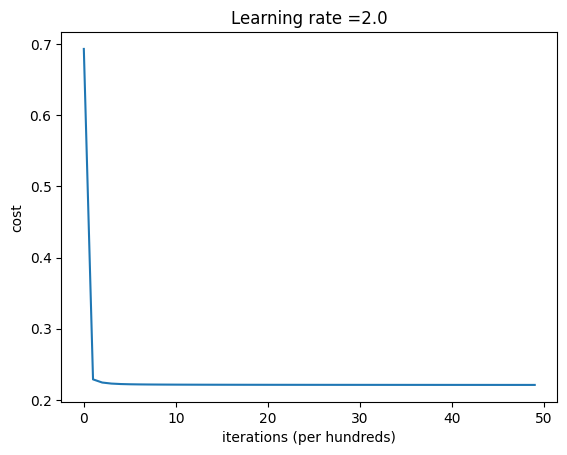

In [13]:
# Plot learning curve (with costs)
costs = np.squeeze(logistic_regression_model['costs'])
plt.plot(costs)
plt.ylabel('cost')
plt.xlabel('iterations (per hundreds)')
plt.title("Learning rate =" + str(logistic_regression_model["learning_rate"]))
plt.show()

In [14]:
#Reverse normalization
Y_prediction_test_real_scale = scaler_y.inverse_transform(logistic_regression_model["Y_prediction_test"].T)
print("test MAE, RMSE, R2:", evaluate(test_set_y_orig, Y_prediction_test_real_scale))

test MAE, RMSE, R2: (np.float64(34.66251978341594), np.float64(57.990593483594026), np.float64(0.9118788704256253))


<a name='7'></a>
##  7 - Results Analysis

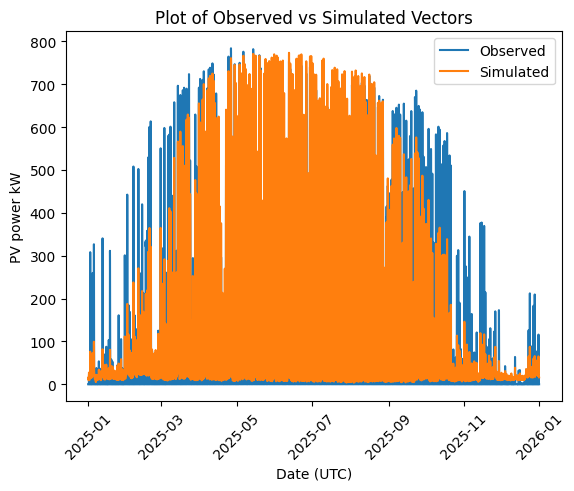

In [15]:
x = time[split:]                               
y1 = test_set_y_orig
y2 = Y_prediction_test_real_scale

plt.plot(x, y1, label='Observed')
plt.plot(x, y2, label='Simulated')
plt.title('Plot of Observed vs Simulated Vectors')
plt.xlabel('Date (UTC)')
plt.ylabel('PV power kW')
plt.ylim()
plt.legend()
plt.xticks(rotation=45)
plt.show()

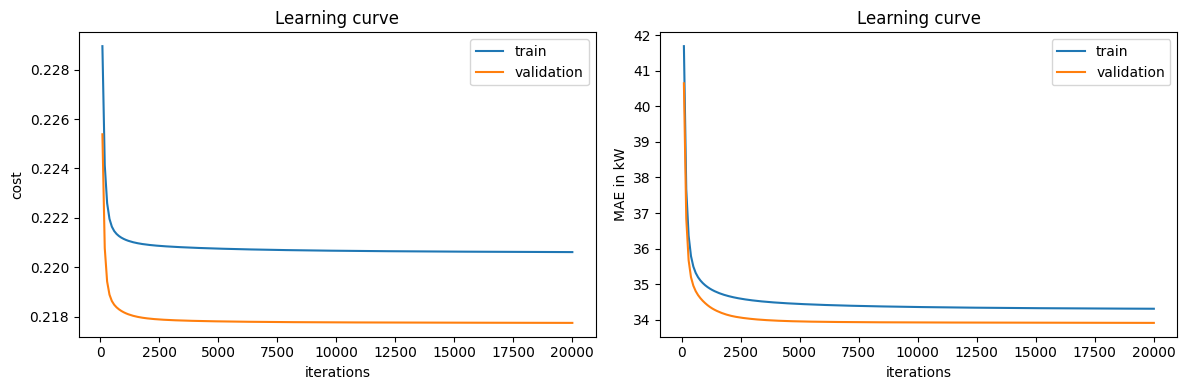

In [16]:
# ---------- learning curves: train vs validation (mean over the CV folds) ----------
total_iterations = 20000   # long enough to see if the validation error starts to rise
step = 100                 # evaluate every 100 iterations
n_points = total_iterations // step

train_cost = np.zeros((n_splits, n_points))
val_cost = np.zeros((n_splits, n_points))
train_mae = np.zeros((n_splits, n_points))
val_mae = np.zeros((n_splits, n_points))

for fold, (train_idx, val_idx) in enumerate(tscv.split(train_set_x_orig)):
    x_train = train_set_x_orig[train_idx]
    x_val = train_set_x_orig[val_idx]
    y_train = train_set_y_orig[train_idx]
    y_val = train_set_y_orig[val_idx]

    # same normalization as in the cross-validation
    scaler_x = MinMaxScaler(feature_range=(0,1))
    scaler_y = MinMaxScaler(feature_range=(0,1))
    x_train_normalized = scaler_x.fit_transform(x_train).T
    x_val_normalized = scaler_x.transform(x_val).T
    y_train_normalized = scaler_y.fit_transform(y_train).T
    y_val_normalized = scaler_y.transform(y_val).T

    y_range = np.max(y_train) - np.min(y_train)    # to convert the normalized error back to kW

    w, b = initialize_with_zeros(x_train_normalized.shape[0])

    for k in range(n_points):
        # continue the training for another 100 iterations
        params, grads, costs = optimize(w, b, x_train_normalized, y_train_normalized, step, learning_rate)
        w = params["w"]
        b = params["b"]

        train_cost[fold, k] = propagate(w, b, x_train_normalized, y_train_normalized)[1]
        val_cost[fold, k] = propagate(w, b, x_val_normalized, y_val_normalized)[1]

        train_mae[fold, k] = np.mean(np.abs(predict(w, b, x_train_normalized) - y_train_normalized)) * y_range
        val_mae[fold, k] = np.mean(np.abs(predict(w, b, x_val_normalized) - y_val_normalized)) * y_range

iterations = np.arange(step, total_iterations + 1, step)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for i, (train_curve, val_curve, label) in enumerate([(train_cost, val_cost, 'cost'), (train_mae, val_mae, 'MAE in kW')]):
    ax[i].plot(iterations, train_curve.mean(axis=0), label='train')
    ax[i].plot(iterations, val_curve.mean(axis=0), label='validation')
    ax[i].set_xlabel('iterations')
    ax[i].set_ylabel(label)
    ax[i].set_title('Learning curve')
    ax[i].legend()

plt.tight_layout()
plt.show()